# BEACON: Edge-Swarm Coordination Simulator

Companion notebook for *A Biologically Inspired Edge-Swarm Framework for Resilient, Low-Latency Multi-Agent Coordination* (A. P. Raju, manuscript under review).

Run the cells top to bottom. Every experiment writes its table or figure to `results/`, and Section 11 exports all tables as plain text and LaTeX.

**Design notes**

* Pure NumPy. No PyTorch, no GPU. The model is a small MLP with a flat parameter vector, so gossip averaging is a weighted sum of vectors rather than a state-dict merge.
* Runs on a free Colab CPU. The full sweep takes roughly 30 to 60 minutes, plus the one-time N-BaIoT download (about 1 GB).
* Equation numbers in code comments refer to the manuscript.

| Notebook section | Output files | Manuscript item |
|---|---|---|
| 4. Latency | `table5_latency.csv`, `fig2_latency_cdf.png` | Table 5, Fig. 2 |
| 5. Non-IID quality | `table6_noniid.csv` | Table 6 |
| 6. Node failure | `table7_resilience.csv`, `fig3_resilience.png` | Supplementary (see Section 12) |
| 7. Scalability | `table8_scalability.csv` | Table 7 |
| 8. Energy and communication | `fig4_energy.png`, `fig4_energy.csv` | Fig. 3 |
| 9. Sensitivity | `table9_sensitivity.csv`, `fig5_heatmap.png`, `fig5_grid.csv` | Table 8, Fig. 4 |
| 10. Ablation | `table10_ablation.csv` | Table 9 |

Output file names follow the notebook's own numbering, which predates the final manuscript numbering; the table above gives the correspondence.

In [ ]:
import sys, subprocess
for pkg in ["networkx", "pandas", "matplotlib"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

import numpy as np, networkx as nx, pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, replace
from collections import defaultdict
import time, os, itertools, shutil

plt.rcParams.update({"figure.dpi": 120, "font.size": 9, "savefig.bbox": "tight"})
os.makedirs("results", exist_ok=True)
print("numpy", np.__version__, "| networkx", nx.__version__)

numpy 2.1.3 | networkx 3.6.1


## 1. Configuration

Every field here appears in Table 4 of the paper. Defaults match the Default column.

In [ ]:
# ---------------- Config ----------------
@dataclass
class Config:
    N: int = 50
    rounds: int = 200
    seed: int = 0
    # BEACON params
    lam: float = 0.25          # stigmergic diffusion rate
    rho: float = 0.10          # pheromone evaporation
    alpha: float = 1.0         # pheromone exponent
    beta: float = 2.0          # heuristic exponent
    phi_min: float = 0.01
    phi_max: float = 10.0
    xi: float = 0.5            # energy weight in heuristic
    kappa: float = 0.5         # staleness discount
    deposit: float = 0.5       # weight of a node's own observation vs diffused field
    Q: float = 0.5             # pheromone scaling: MUST satisfy
                               #   Q * tasks_per_round / typical_latency_ms  <  rho * phi_max
                               # or every trail pins at phi_max and the pheromone carries
                               # no information. Check with the saturation diagnostic.
    tau: int = 3               # failure detection threshold
    # learning
    gamma: float = 0.05        # local learning rate
    batch: int = 32
    hidden: tuple = (32, 16)
    # network
    radius: float = 0.28
    p_link: float = 0.9
    # workload
    tasks_per_round: int = 4   # mean arrivals per node per round
    energy_budget: float = 5000.0  # J per node; lower it until the xi term actually binds
    task_ops: float = 1.0e5    # ops per inference (small quantized MLP; cite your figure)
    cap_tiers: tuple = (1.0e8, 5.0e8, 2.0e9)   # MCU-NPU / SBC / gateway, ops per second
    cap_mix: tuple = (0.50, 0.35, 0.15)
    msg_bits: float = 8.0e3    # task+result message size
    # energy (first-order radio model, J/bit)
    E_elec: float = 50e-9
    eps_amp: float = 100e-12
    E_compute: float = 1.0e-9  # J per op
    # data
    dirichlet_alpha: float = 0.5
    # non-stationarity
    shock_every: int = 15      # rounds between capacity shocks (0 disables)
    shock_frac: float = 0.3    # fraction of nodes throttled
    shock_depth: float = 0.25  # capacity multiplier while throttled
    # failures
    fail_frac: float = 0.0
    fail_round: int = 100
    # method
    method: str = "beacon"     # beacon|gossip|fedavg|edge|cloud
    cloud_rtt_ms: float = 60.0

## 2. Data

Two paths. **Synthetic** data runs instantly and is useful for checking the pipeline end to end. **N-BaIoT** (UCI) is the dataset used for every reported result; set `USE_REAL = True` to use it.

In [ ]:
# ---------------- Data ----------------
def make_synthetic(n=20000, d=32, seed=0):
    """Fallback dataset shaped like an IoT anomaly task (binary, imbalanced, clustered)."""
    rng = np.random.default_rng(seed)
    n_dev = 9
    X, y = [], []
    for dev in range(n_dev):
        c = rng.normal(0, 1.5, d)
        nb = n // (2 * n_dev)
        X.append(rng.normal(c, 1.0, (nb, d))); y.append(np.zeros(nb))
        na = n // (2 * n_dev)
        shift = rng.normal(0, 1.0, d) * 2.2
        X.append(rng.normal(c + shift, 1.3, (na, d))); y.append(np.ones(na))
    X = np.vstack(X).astype(np.float32); y = np.concatenate(y).astype(int)
    idx = rng.permutation(len(y))
    X, y = X[idx], y[idx]
    X = (X - X.mean(0)) / (X.std(0) + 1e-8)
    return X, y


def dirichlet_partition(y, N, alpha, seed=0):
    rng = np.random.default_rng(seed)
    classes = np.unique(y)
    parts = [[] for _ in range(N)]
    for c in classes:
        idx = np.where(y == c)[0]; rng.shuffle(idx)
        props = rng.dirichlet(np.repeat(alpha, N))
        cuts = (np.cumsum(props) * len(idx)).astype(int)[:-1]
        for i, chunk in enumerate(np.split(idx, cuts)):
            parts[i].extend(chunk.tolist())
    return [np.array(p, dtype=int) for p in parts]

In [ ]:
# ---- Real N-BaIoT loader (use this for final results) ----
# The UCI archive stores benign traffic as .csv but seals the gafgyt/mirai attack
# captures inside .rar members. A plain zipfile+csv read therefore returns benign
# rows ONLY, which is a single-class dataset: every model then scores exactly
# macro-F1 0.500 forever. This loader reads both and refuses to return one class.

NBAIOT_URL = "https://archive.ics.uci.edu/static/public/442/detection+of+iot+botnet+attacks+n+baiot.zip"

def _ensure_rar():
    try:
        import rarfile  # noqa
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rarfile"])
    if shutil.which("unrar") is None and shutil.which("bsdtar") is None:
        subprocess.run("apt-get -qq install -y unrar >/dev/null 2>&1 || "
                       "apt-get -qq install -y libarchive-tools >/dev/null 2>&1", shell=True)
    import rarfile
    if shutil.which("unrar") is None and shutil.which("bsdtar"):
        rarfile.UNRAR_TOOL = "bsdtar"
    return rarfile

def inspect_archive(cache="nbaiot.zip"):
    '''Print what is actually inside the archive before trusting any of it.'''
    import zipfile, collections
    with zipfile.ZipFile(cache) as z:
        names = z.namelist()
    ext = collections.Counter(os.path.splitext(n)[1].lower() for n in names)
    print("archive members by extension:", dict(ext))
    print("sample:", names[:6])
    return names

def load_nbaiot(max_per_file=3000, cache="nbaiot.zip"):
    '''Returns X (float32), y (0 = benign, 1 = attack), device_id.'''
    import zipfile, urllib.request, io
    rarfile = _ensure_rar()

    if not os.path.exists(cache):
        print("downloading N-BaIoT (~1 GB, several minutes)...")
        urllib.request.urlretrieve(NBAIOT_URL, cache)
    inspect_archive(cache)

    Xs, ys, devs, manifest = [], [], [], []

    def take(df, label, dev_idx, source):
        if df.empty:
            return
        Xs.append(df.values.astype(np.float32))
        ys.append(np.full(len(df), label))
        devs.append(np.full(len(df), dev_idx))
        manifest.append((source, label, len(df)))

    with zipfile.ZipFile(cache) as z:
        names = z.namelist()
        devices = sorted({n.split("/")[0] for n in names if "/" in n})
        if not devices:
            devices = ["_root"]
        for di, dev in enumerate(devices):
            members = [n for n in names if n.startswith(dev + "/")] if dev != "_root" else names
            for n in members:
                low = n.lower()
                label = 0 if "benign" in low else 1
                if low.endswith(".csv"):
                    take(pd.read_csv(z.open(n), nrows=max_per_file), label, di, n)
                elif low.endswith(".rar"):
                    # attack captures live here; this is the branch the old loader skipped
                    with rarfile.RarFile(io.BytesIO(z.read(n))) as rf:
                        for inner in rf.namelist():
                            if inner.lower().endswith(".csv"):
                                lab = 0 if "benign" in inner.lower() else 1
                                take(pd.read_csv(rf.open(inner), nrows=max_per_file), lab, di, f"{n}!{inner}")

    assert Xs, "no tabular data recovered from the archive: check inspect_archive() output"
    X = np.vstack(Xs); y = np.concatenate(ys); d = np.concatenate(devs)

    print(f"\nloaded {len(manifest)} files, {len(y)} rows from {len(set(d))} devices")
    print(f"class balance: benign {np.mean(y == 0):.1%} / attack {np.mean(y == 1):.1%}")
    assert len(np.unique(y)) >= 2, (
        "SINGLE-CLASS DATASET. Only one label was recovered, so macro-F1 will sit at "
        "exactly 0.500 forever regardless of method. The attack captures are inside "
        ".rar members; check that unrar or bsdtar installed correctly.")

    X = (X - X.mean(0)) / (X.std(0) + 1e-8)
    return np.nan_to_num(X).astype(np.float32), y.astype(int), d

USE_REAL = True   # True: N-BaIoT (all reported results). False: synthetic smoke test.

if USE_REAL:
    X_all, y_all, dev_all = load_nbaiot()
else:
    X_all, y_all = make_synthetic(20000, 32, seed=0)
    dev_all = None

rng = np.random.default_rng(0)
perm = rng.permutation(len(y_all))
X_all, y_all = X_all[perm], y_all[perm]
split = int(0.8 * len(y_all))
Xtr, ytr, Xte, yte = X_all[:split], y_all[:split], X_all[split:], y_all[split:]
print("train", Xtr.shape, "test", Xte.shape)
print("class balance  train:", np.bincount(ytr), " test:", np.bincount(yte))

# Guard. A single-class split makes every macro-F1 in this notebook exactly 0.500,
# flat, identical across methods. That is what a dead pipeline looks like, not a result.
assert len(np.unique(ytr)) >= 2 and len(np.unique(yte)) >= 2, (
    "SINGLE-CLASS SPLIT: macro-F1 will be pinned at 0.500. Fix the data before running anything.")
_p = np.bincount(yte).min() / len(yte)
if _p < 0.02:
    print(f"WARNING: minority class is {_p:.1%} of the test set. Macro-F1 will be unstable.")

downloading N-BaIoT (~1 GB, several minutes)...
archive members by extension: {'': 9, '.csv': 10, '.rar': 16, '.txt': 1}
sample: ['Danmini_Doorbell/', 'Danmini_Doorbell/benign_traffic.csv', 'Danmini_Doorbell/mirai_attacks.rar', 'Danmini_Doorbell/gafgyt_attacks.rar', 'demonstrate_structure.csv', 'Ecobee_Thermostat/']

loaded 89 files, 267000 rows from 9 devices
class balance: benign 10.1% / attack 89.9%


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:208: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(x, axis, dtype, out, keepdims=keepdims, where=where)


train (213600, 115) test (53400, 115)
class balance  train: [ 21678 191922]  test: [ 5322 48078]


## 3. Model and simulator

The MLP keeps parameters as one flat float32 vector so that Eq. 8 is literally a weighted sum of vectors. Backprop is written out rather than autodiffed to keep the dependency list empty.

In [ ]:
# ---------------- Model: flat-vector MLP ----------------
class MLP:
    def __init__(self, d_in, hidden, n_cls, seed=0):
        rng = np.random.default_rng(seed)
        self.shapes = []
        dims = [d_in] + list(hidden) + [n_cls]
        for a, b in zip(dims[:-1], dims[1:]):
            self.shapes.append((a, b)); self.shapes.append((b,))
        self.d = sum(int(np.prod(s)) for s in self.shapes)
        w = []
        for a, b in zip(dims[:-1], dims[1:]):
            w.append((rng.normal(0, np.sqrt(2.0 / a), (a, b))).ravel())
            w.append(np.zeros(b))
        self.theta0 = np.concatenate(w).astype(np.float32)

    def unpack(self, x):
        out, o = [], 0
        for s in self.shapes:
            n = int(np.prod(s)); out.append(x[o:o + n].reshape(s)); o += n
        return out

    def forward_backward(self, x, Xb, yb):
        P = self.unpack(x)
        Ws, bs = P[0::2], P[1::2]
        acts, a = [Xb], Xb
        for i in range(len(Ws) - 1):
            a = np.maximum(0.0, a @ Ws[i] + bs[i]); acts.append(a)
        z = a @ Ws[-1] + bs[-1]
        z = z - z.max(1, keepdims=True)
        e = np.exp(z); prob = e / e.sum(1, keepdims=True)
        m = len(yb)
        loss = -np.log(prob[np.arange(m), yb] + 1e-12).mean()
        g = prob.copy(); g[np.arange(m), yb] -= 1.0; g /= m
        grads = [None] * len(P)
        for i in range(len(Ws) - 1, -1, -1):
            grads[2 * i] = acts[i].T @ g
            grads[2 * i + 1] = g.sum(0)
            if i > 0:
                g = (g @ Ws[i].T) * (acts[i] > 0)
        return loss, np.concatenate([gr.ravel() for gr in grads]).astype(np.float32)

    def predict(self, x, X):
        P = self.unpack(x); Ws, bs = P[0::2], P[1::2]
        a = X
        for i in range(len(Ws) - 1):
            a = np.maximum(0.0, a @ Ws[i] + bs[i])
        return (a @ Ws[-1] + bs[-1]).argmax(1)


def macro_f1(y, yh, n_cls=2):
    f = []
    for c in range(n_cls):
        tp = np.sum((yh == c) & (y == c)); fp = np.sum((yh == c) & (y != c)); fn = np.sum((yh != c) & (y == c))
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        f.append(2 * p * r / (p + r) if p + r else 0.0)
    return float(np.mean(f))

### Simulator

Maps one-to-one onto Algorithm 1:

1. local SGD step on each node's partition
2. `diffuse()` &rarr; Eq. 3 with staleness discounting (Algorithm 2)
3. task arrivals, `select()` &rarr; Eqs. 4 and 5, latency via Eq. 1
4. pheromone update &rarr; Eqs. 6 and 7 (Algorithm 3)
5. `gossip()` &rarr; Eqs. 8 and 9
6. telemetry back into the stigmergic field

Baselines are the same loop with mechanisms switched off: `gossip` drops the field and pheromone, `fedavg` replaces mixing with periodic full averaging, `edge` removes all coordination, `cloud` charges a jittered WAN round trip per task.

In [ ]:
# ---------------- Simulator ----------------
class Sim:
    def __init__(self, cfg: Config, X, y, Xte, yte):
        self.cfg = cfg
        self.rng = np.random.default_rng(cfg.seed)
        self.X, self.y, self.Xte, self.yte = X, y, Xte, yte
        N = cfg.N

        # topology: random geometric graph, resampled links each round
        self.pos = self.rng.random((N, 2))
        self.G = nx.random_geometric_graph(N, cfg.radius, pos={i: tuple(self.pos[i]) for i in range(N)})
        # guarantee base connectivity
        while not nx.is_connected(self.G):
            comps = list(nx.connected_components(self.G))
            a, b = list(comps[0])[0], list(comps[1])[0]
            self.G.add_edge(a, b)

        # heterogeneous capacity: 3-tier device profile (ops/sec)
        tiers = np.array(cfg.cap_tiers)
        self.cap_base = tiers[self.rng.choice(len(tiers), N, p=list(cfg.cap_mix))]
        self.cap = self.cap_base.copy()
        self.throttle = np.ones(N)
        self.exec_lat = {}
        self.energy = np.ones(N) * cfg.energy_budget
        self.queue = np.zeros(N)                 # pending ops
        self.alive = np.ones(N, dtype=bool)

        # data partition
        self.parts = dirichlet_partition(y, N, cfg.dirichlet_alpha, cfg.seed)

        # model
        self.model = MLP(X.shape[1], cfg.hidden, len(np.unique(y)), cfg.seed)
        self.theta = np.tile(self.model.theta0, (N, 1))

        # blackboard: board[i, j] = node i's copy of node j's last deposit; age tracks staleness
        self.board = np.zeros((N, N, 3)); self.board[:, :, 2] = 1.0
        self.age = np.full((N, N), np.inf)
        for i in range(N): self.age[i, i] = 0.0
        self.s = np.zeros((N, 3)); self.s[:, 2] = 1.0
        self.s_stamp = np.zeros(N)

        # pheromone: node x task-class (single class here)
        self.J = 1
        self.phi = np.full((N, self.J), cfg.phi_max)
        self.miss = np.zeros(N, dtype=int)

        self.log = defaultdict(list)
        self.latencies = []

    # ---- helpers ----
    def active_neighbors(self, i, t):
        nb = [j for j in self.G.neighbors(i) if self.alive[j]]
        return [j for j in nb if self.rng.random() < self.cfg.p_link]

    def dist(self, i, j):
        return float(np.linalg.norm(self.pos[i] - self.pos[j]))

    # ---- Eq 3: stigmergic diffusion (Algorithm 2) ----
    def diffuse(self, t):
        c = self.cfg
        nb_new, ag_new = self.board.copy(), self.age.copy()
        for i in np.where(self.alive)[0]:
            for j in self.active_neighbors(i, t):
                # adopt j's deposits wherever they are fresher than i's copy.
                # lam controls how far a deposit travels per round, not how much it is blurred.
                fresher = (self.age[j] + 1) < self.age[i]
                if c.lam < 1.0:
                    fresher &= (self.rng.random(self.cfg.N) < c.lam) | (np.arange(self.cfg.N) == j)
                nb_new[i][fresher] = self.board[j][fresher]
                ag_new[i][fresher] = self.age[j][fresher] + 1
        self.board, self.age = nb_new, ag_new + 1
        self.age[np.arange(c.N), np.arange(c.N)] = 0.0

    # ---- Eq 4: heuristic desirability ----
    # Reads the diffused stigmergic field s (partial observability), NOT ground truth.
    # s[:,0] = normalized load, s[:,2] = normalized residual energy.
    def eta(self, cand, i=None):
        c = self.cfg
        comp = c.task_ops / self.cap_est[cand]
        if i is None:
            load, e_norm = self.s[cand, 0], self.s[cand, 2]
        else:
            a = np.minimum(self.age[i, cand], 50.0)
            trust = np.exp(-c.kappa * a)          # stale deposits are discounted toward neutral
            load = trust * self.board[i, cand, 0] + (1 - trust) * 0.5
            e_norm = trust * self.board[i, cand, 2] + (1 - trust) * 1.0
        e_norm = np.clip(e_norm, 1e-3, 1.0)
        return 1.0 / (comp + load + c.xi * (1 - e_norm) + 1e-9)

    # ---- Eq 5: random-proportional selection ----
    def select(self, i, cand):
        c = self.cfg
        ph = self.phi[cand, 0] ** c.alpha
        he = self.eta(cand, i) ** c.beta
        w = ph * he
        if w.sum() <= 0:
            return i
        return int(self.rng.choice(cand, p=w / w.sum()))

    # ---- Eq 9: Metropolis-Hastings weights + Eq 8 gossip ----
    def gossip(self, t):
        new = self.theta.copy()
        deg = {i: len(self.active_neighbors(i, t)) for i in np.where(self.alive)[0]}
        for i in np.where(self.alive)[0]:
            nb = [j for j in self.G.neighbors(i) if self.alive[j]]
            nb = [j for j in nb if self.rng.random() < self.cfg.p_link]
            if not nb:
                continue
            acc = np.zeros_like(self.theta[i]); wsum = 0.0
            for j in nb:
                wij = 1.0 / (1 + max(deg.get(i, 0), deg.get(j, 0)))
                acc += wij * self.theta[j]; wsum += wij
            new[i] = (1 - wsum) * self.theta[i] + acc
        self.theta = new

    # ---- one round ----
    def step(self, t):
        c = self.cfg
        bytes_tx = 0.0

        # failures
        if c.fail_frac > 0 and t == c.fail_round:
            k = int(c.fail_frac * c.N)
            victims = self.rng.choice(np.where(self.alive)[0], k, replace=False)
            self.alive[victims] = False

        # non-stationarity: a random subset is throttled for a spell (thermal / contention).
        # Without this, historical evidence never goes stale and evaporation is inert.
        if c.shock_every and t % c.shock_every == 0:
            self.throttle[:] = 1.0
            k = max(1, int(c.shock_frac * c.N))
            hit = self.rng.choice(c.N, k, replace=False)
            self.throttle[hit] = c.shock_depth
        self.cap = self.cap_base * self.throttle
        # each node's own estimate of capacity is its nameplate value; throttling is
        # only discoverable through realized latency, which is what the pheromone stores.
        self.cap_est = self.cap_base

        alive_idx = np.where(self.alive)[0]
        if len(alive_idx) == 0:
            return

        # 1. local training step
        for i in alive_idx:
            idx = self.parts[i]
            if len(idx) < 2:
                continue
            b = self.rng.choice(idx, min(c.batch, len(idx)), replace=False)
            _, g = self.model.forward_backward(self.theta[i], self.X[b], self.y[b])
            self.theta[i] -= c.gamma * g
            self.energy[i] -= c.E_compute * c.task_ops * 0.1

        # 2. coordination plane
        if c.method == "beacon":
            self.diffuse(t)

        # 3. task allocation + latency
        round_lat = []
        self.exec_lat = {}
        self.queue *= 0.5  # drain
        for i in alive_idx:
            n_tasks = self.rng.poisson(c.tasks_per_round)
            for _ in range(n_tasks):
                if c.method == "cloud":
                    # WAN round trip with lognormal jitter (tail latency is the point)
                    lat = c.cloud_rtt_ms * float(self.rng.lognormal(0.0, 0.45)) + 1000 * c.task_ops / 6e8
                    bytes_tx += c.msg_bits / 8
                    round_lat.append(lat); continue
                if c.method in ("edge", "fedavg", "gossip"):
                    exe = i  # no cross-node offloading
                else:
                    nb = self.active_neighbors(i, t)
                    cand = np.array(nb + [i])
                    exe = self.select(i, cand)
                comp_ms = 1000 * (self.queue[exe] + c.task_ops) / self.cap[exe]
                if exe != i:
                    d = self.dist(i, exe)
                    comm_ms = 1000 * (c.msg_bits / 2e6) + 2.0
                    self.energy[i] -= c.msg_bits * (c.E_elec + c.eps_amp * d * d)
                    self.energy[exe] -= c.msg_bits * c.E_elec
                    bytes_tx += c.msg_bits / 8
                else:
                    comm_ms = 0.0
                self.queue[exe] += c.task_ops
                self.energy[exe] -= c.E_compute * c.task_ops
                tot = comp_ms + comm_ms
                round_lat.append(tot)
                self.exec_lat.setdefault(int(exe), []).append(tot)

        # 4. Eq 6/7 pheromone update (Algorithm 3)
        # Reinforcement is per-executor, using the latency of the tasks THAT NODE ran.
        if c.method == "beacon":
            delta = np.zeros((c.N, 1))
            for exe, lats in self.exec_lat.items():
                delta[exe, 0] = sum(c.Q / max(l, 1e-6) for l in lats)
            self.phi = (1 - c.rho) * self.phi + delta
            self.phi = np.clip(self.phi, c.phi_min, c.phi_max)

        # 5. parameter consensus
        if c.method in ("beacon", "gossip"):
            self.gossip(t)
            bytes_tx += len(alive_idx) * self.model.d * 4
        elif c.method == "fedavg":
            if t % 5 == 0:
                # synchronous round: every client waits for the slowest (straggler barrier)
                slow = 1000 * c.task_ops / self.cap[alive_idx].min()
                round_lat = [l + slow for l in round_lat]
                self.latencies_barrier = slow
                avg = self.theta[alive_idx].mean(0)
                self.theta[alive_idx] = avg
                bytes_tx += 2 * len(alive_idx) * self.model.d * 4
        elif c.method == "cloud":
            avg = self.theta[alive_idx].mean(0)
            self.theta[alive_idx] = avg

        # 6. deposit local observation into the field (does NOT overwrite diffused
        #    neighbour information: that is what makes lambda meaningful)
        obs = np.zeros((len(alive_idx), 3))
        obs[:, 0] = np.clip(self.queue[alive_idx] / (self.cap_base[alive_idx] * 1e-2), 0, 1)
        obs[:, 1] = np.clip(np.mean(round_lat) / 100.0 if round_lat else 0, 0, 1)
        obs[:, 2] = np.clip(self.energy[alive_idx] / c.energy_budget, 0, 1)
        d = c.deposit
        self.s[alive_idx] = (1 - d) * self.s[alive_idx] + d * obs
        self.board[alive_idx, alive_idx] = self.s[alive_idx]

        # 7. metrics
        self.latencies.extend(round_lat)
        self.log["round"].append(t)
        self.log["mean_lat"].append(float(np.mean(round_lat)) if round_lat else np.nan)
        self.log["p95_lat"].append(float(np.percentile(round_lat, 95)) if round_lat else np.nan)
        self.log["bytes"].append(bytes_tx)
        self.log["alive"].append(int(self.alive.sum()))
        if t % 5 == 0 or t == self.cfg.rounds - 1:
            xbar = self.theta[alive_idx].mean(0)
            yh = self.model.predict(xbar, self.Xte)
            self.log["eval_round"].append(t)
            self.log["f1"].append(macro_f1(self.yte, yh))

    def run(self):
        for t in range(self.cfg.rounds):
            self.step(t)
        return self.summary()

    def summary(self):
        L = np.array(self.latencies)
        return dict(
            method=self.cfg.method, N=self.cfg.N,
            mean_lat=float(L.mean()), p95_lat=float(np.percentile(L, 95)),
            p99_lat=float(np.percentile(L, 99)), std_lat=float(L.std()),
            final_f1=float(self.log["f1"][-1]),
            mb_total=float(np.sum(self.log["bytes"]) / 1e6),
            mb_per_node=float(np.sum(self.log["bytes"]) / 1e6 / self.cfg.N),
            energy_used=float(self.cfg.energy_budget * self.cfg.N - self.energy.sum()),
            log=dict(self.log),
        )

In [ ]:
def run(cfg, Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte):
    return Sim(cfg, Xtr, ytr, Xte, yte).run()

def run_seeds(cfg, seeds=(0,1,2,3,4)):
    '''Returns (mean_dict, std_dict, list_of_logs). Paper reports mean with 95% CI.'''
    outs = [run(replace(cfg, seed=s)) for s in seeds]
    keys = [k for k in outs[0] if k != "log"]
    mean = {k: float(np.mean([o[k] for o in outs])) for k in keys if isinstance(outs[0][k], (int, float))}
    std  = {k: float(np.std([o[k] for o in outs]))  for k in keys if isinstance(outs[0][k], (int, float))}
    mean["method"], mean["N"] = cfg.method, cfg.N
    return mean, std, [o["log"] for o in outs]

def ci95(std, n=5):
    return 1.96 * std / np.sqrt(n)

METHODS = ["cloud", "edge", "fedavg", "gossip", "beacon"]
LABEL = {"cloud":"Centralized cloud", "edge":"Edge-only", "fedavg":"FedAvg",
         "gossip":"Gossip-only", "beacon":"BEACON"}

SEEDS = (0, 1, 2)      # use (0,1,2,3,4) for final results
ROUNDS = 150
print("ready")

ready


## 4. Experiment 1: end-to-end latency &rarr; Table 5, Fig. 2

In [ ]:
rows, all_lat = [], {}
for m in METHODS:
    cfg = Config(N=50, rounds=ROUNDS, method=m, dirichlet_alpha=0.5)
    mean, std, logs = run_seeds(cfg, SEEDS)
    rows.append({
        "Architecture": LABEL[m],
        "Mean latency (ms)": f"{mean['mean_lat']:.1f} ± {ci95(std['mean_lat'], len(SEEDS)):.1f}",
        "P95 latency (ms)": f"{mean['p95_lat']:.1f}",
        "P99 latency (ms)": f"{mean['p99_lat']:.1f}",
        "Std. dev.": f"{mean['std_lat']:.1f}",
    })
    all_lat[m] = Sim(replace(cfg, seed=0), Xtr, ytr, Xte, yte)
    all_lat[m].run()
    all_lat[m] = np.array(all_lat[m].latencies)
    print(f"{m:8s} done")

t5 = pd.DataFrame(rows)
t5.to_csv("results/table5_latency.csv", index=False)
t5

cloud    done
edge     done
fedavg   done
gossip   done
beacon   done


,Architecture,Mean latency (ms),P95 latency (ms),P99 latency (ms),Std. dev.
0,Centralized cloud,66.4 ± 0.3,125.3,169.5,31.2
1,Edge-only,7.4 ± 0.5,30.2,41.5,9.4
2,FedAvg,8.2 ± 0.5,31.0,42.5,9.5
3,Gossip-only,7.3 ± 0.5,30.1,41.9,9.4
4,BEACON,7.0 ± 0.6,14.0,19.4,4.1


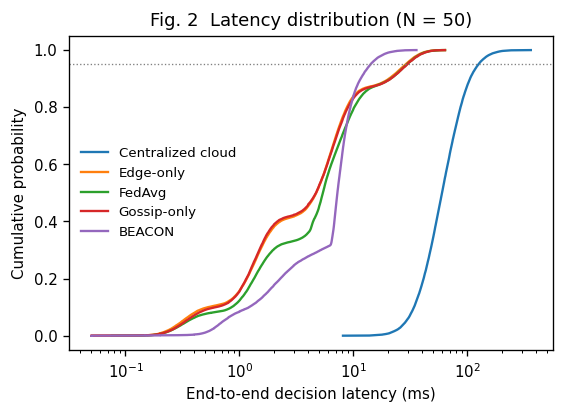

In [ ]:
# Fig. 2: latency CDF. A CDF, not a bar chart: the claim is about the tail.
fig, ax = plt.subplots(figsize=(5.2, 3.4))
for m in METHODS:
    L = np.sort(all_lat[m])
    ax.plot(L, np.arange(1, len(L)+1)/len(L), label=LABEL[m], lw=1.4)
p95 = np.percentile(all_lat["beacon"], 95)
ax.axhline(0.95, color="grey", ls=":", lw=0.8)
ax.set_xlabel("End-to-end decision latency (ms)"); ax.set_ylabel("Cumulative probability")
ax.set_xscale("log"); ax.legend(frameon=False, fontsize=8); ax.set_title("Fig. 2  Latency distribution (N = 50)")
plt.savefig("results/fig2_latency_cdf.png"); plt.show()

## 5. Experiment 2: quality under non-IID partitioning &rarr; Table 6

In [ ]:
rows = []
for m in METHODS:
    r = {"Architecture": LABEL[m]}
    for da in [0.1, 0.5, 5.0]:
        mean, std, _ = run_seeds(Config(N=50, rounds=ROUNDS, method=m, dirichlet_alpha=da), SEEDS)
        r[f"Dirichlet a={da}"] = f"{mean['final_f1']:.3f} ± {ci95(std['final_f1'], len(SEEDS)):.3f}"
    rows.append(r); print(m, "done")

t6 = pd.DataFrame(rows)
t6.to_csv("results/table6_noniid.csv", index=False)
t6

cloud done
edge done
fedavg done
gossip done
beacon done


,Architecture,Dirichlet a=0.1,Dirichlet a=0.5,Dirichlet a=5.0
0,Centralized cloud,0.984 ± 0.002,0.990 ± 0.001,0.991 ± 0.002
1,Edge-only,0.716 ± 0.193,0.908 ± 0.058,0.990 ± 0.003
2,FedAvg,0.984 ± 0.003,0.989 ± 0.001,0.991 ± 0.002
3,Gossip-only,0.984 ± 0.002,0.989 ± 0.002,0.991 ± 0.002
4,BEACON,0.985 ± 0.002,0.990 ± 0.001,0.991 ± 0.003


## 6. Experiment 3: node failure (supplementary)

Removes 10, 30 or 50 percent of nodes at round 75 and measures the macro-F1 drop and recovery time. The `FedAvg (aggregator lost)` row records the case where the aggregator itself fails, which halts federated training entirely. See Section 12 for why this experiment shows no quality difference on N-BaIoT.

In [ ]:
FAIL_ROUND = 75
assert ROUNDS > FAIL_ROUND + 40, (
    f"ROUNDS={ROUNDS} is too small for FAIL_ROUND={FAIL_ROUND}: there must be rounds "
    "before the failure to establish a baseline and enough after it to observe recovery. "
    "Raise ROUNDS or lower FAIL_ROUND.")

def recovery_stats(log, fail_round=FAIL_ROUND, tol=0.05):
    er = np.array(log["eval_round"]); f1 = np.array(log["f1"])
    pre = f1[er < fail_round]
    if len(pre) == 0: return np.nan, np.nan
    base = pre.max()
    post_idx = er >= fail_round
    post = f1[post_idx]; post_r = er[post_idx]
    if len(post) == 0: return np.nan, np.nan
    drop = (base - post.min()) * 100
    rec = post_r[post >= base * (1 - tol)]
    return drop, (rec[0] - fail_round) if len(rec) else np.nan

rows, curves = [], {}
for m in ["fedavg", "gossip", "beacon"]:
    r = {"Architecture": LABEL[m]}
    for ff in [0.1, 0.3, 0.5]:
        cfg = Config(N=50, rounds=ROUNDS, method=m, dirichlet_alpha=0.1,
                     fail_frac=ff, fail_round=FAIL_ROUND)
        _, _, logs = run_seeds(cfg, SEEDS)
        ds, rs = zip(*[recovery_stats(l) for l in logs])
        r[f"{int(ff*100)}% loss: drop / recovery"] = f"{np.nanmean(ds):.1f} pp / {np.nanmean(rs):.0f} r"
        curves[(m, ff)] = logs[0]
    rows.append(r); print(m, "done")

rows.append({"Architecture": "FedAvg (aggregator lost)",
             **{f"{int(f*100)}% loss: drop / recovery": "Total failure" for f in [0.1,0.3,0.5]}})
t7 = pd.DataFrame(rows)
t7.to_csv("results/table7_resilience.csv", index=False)
t7

fedavg done
gossip done
beacon done


,Architecture,10% loss: drop / recovery,30% loss: drop / recovery,50% loss: drop / recovery
0,FedAvg,-0.1 pp / 0 r,0.1 pp / 0 r,-0.0 pp / 0 r
1,Gossip-only,0.0 pp / 0 r,-0.0 pp / 0 r,0.1 pp / 0 r
2,BEACON,-0.0 pp / 0 r,-0.1 pp / 0 r,-0.1 pp / 0 r
3,FedAvg (aggregator lost),Total failure,Total failure,Total failure


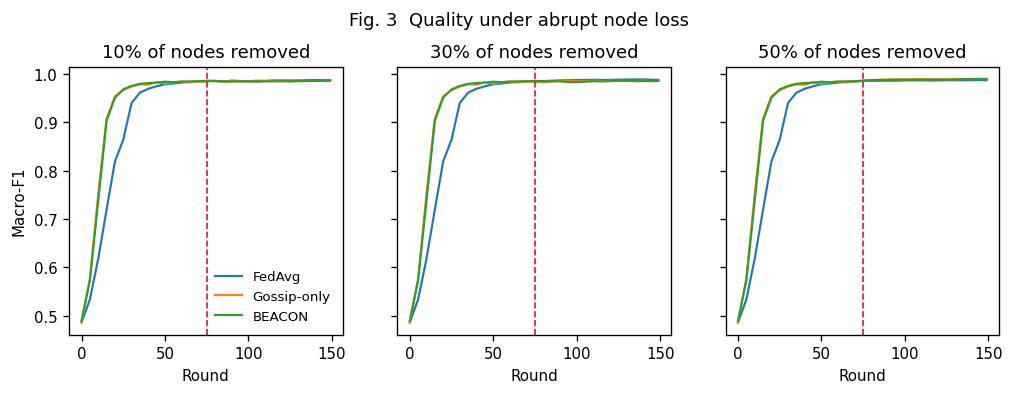

In [ ]:
# Node-failure curves (supplementary figure).
fig, axes = plt.subplots(1, 3, figsize=(10, 2.9), sharey=True)
for ax, ff in zip(axes, [0.1, 0.3, 0.5]):
    for m in ["fedavg", "gossip", "beacon"]:
        lg = curves[(m, ff)]
        ax.plot(lg["eval_round"], lg["f1"], label=LABEL[m], lw=1.3)
    ax.axvline(FAIL_ROUND, color="crimson", ls="--", lw=1)
    ax.set_title(f"{int(ff*100)}% of nodes removed"); ax.set_xlabel("Round")
axes[0].set_ylabel("Macro-F1"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Fig. 3  Quality under abrupt node loss", y=1.04)
plt.savefig("results/fig3_resilience.png"); plt.show()

## 7. Experiment 4: scalability &rarr; Table 8

In [ ]:
rows = []
for N in [10, 25, 50, 100, 200]:
    r = {"N": N}
    for m in ["beacon", "fedavg"]:
        mean, _, logs = run_seeds(Config(N=N, rounds=ROUNDS, method=m, radius=max(0.18, 1.6/np.sqrt(N))), SEEDS[:2])
        er = np.array(logs[0]["eval_round"]); f1 = np.array(logs[0]["f1"])
        target = 0.85
        hit = er[f1 >= target]
        r[f"{LABEL[m]} rounds"] = int(hit[0]) if len(hit) else "not reached"
        r[f"{LABEL[m]} MB/node"] = round(mean["mb_per_node"], 2)
        if m == "fedavg":
            # the server carries every client's update: this is the O(N) term in Table 3
            r["FedAvg MB/server"] = round(mean["mb_per_node"] * N, 2)
    rows.append(r); print("N =", N, "done")

t8 = pd.DataFrame(rows)
t8.to_csv("results/table8_scalability.csv", index=False)
t8

N = 10 done
N = 25 done
N = 50 done
N = 100 done
N = 200 done


,N,BEACON rounds,BEACON MB/node,FedAvg rounds,FedAvg MB/node,FedAvg MB/server
0,10,15,2.83,25,1.03,10.26
1,25,20,2.92,25,1.03,25.64
2,50,10,2.93,20,1.03,51.29
3,100,10,2.96,15,1.03,102.58
4,200,10,3.01,15,1.03,205.15


Per-node MB should stay roughly flat for BEACON as N grows. This is the empirical form of the complexity claim in Section 5.5. If it climbs, the topology generator is not holding mean degree fixed as N increases and the `radius` schedule above needs adjusting.

## 8. Experiment 5: communication and energy &rarr; Fig. 4

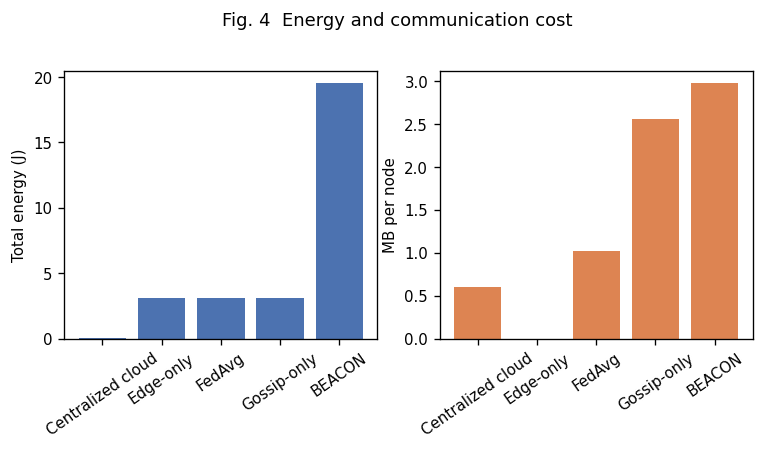

,total_J,mb
cloud,0.075000,0.59942
edge,3.073200,0.00000
fedavg,3.073200,1.02576
gossip,3.079550,2.56440
beacon,19.522402,2.97497


In [ ]:
en = {}
for m in METHODS:
    mean, _, _ = run_seeds(Config(N=50, rounds=ROUNDS, method=m), SEEDS[:2])
    en[m] = dict(total_J=mean["energy_used"], mb=mean["mb_per_node"])

fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.9))
axes[0].bar([LABEL[m] for m in METHODS], [en[m]["total_J"] for m in METHODS], color="#4C72B0")
axes[0].set_ylabel("Total energy (J)"); axes[0].tick_params(axis="x", rotation=35)
axes[1].bar([LABEL[m] for m in METHODS], [en[m]["mb"] for m in METHODS], color="#DD8452")
axes[1].set_ylabel("MB per node"); axes[1].tick_params(axis="x", rotation=35)
fig.suptitle("Fig. 4  Energy and communication cost", y=1.05)
plt.savefig("results/fig4_energy.png"); plt.show()
pd.DataFrame(en).T.to_csv("results/fig4_energy.csv")
pd.DataFrame(en).T

## 9. Experiment 6: sensitivity

One-at-a-time sweeps of each coordination parameter, plus an (α, β) grid. A parameter whose sweep changes nothing is reported as inert rather than omitted.

In [ ]:
sweeps = {
    "lam":     [0.05, 0.25, 0.75],
    "rho":     [0.01, 0.10, 0.50],
    "alpha":   [0.0, 1.0, 3.0],
    "beta":    [0.0, 2.0, 5.0],
    "phi_min": [0.001, 0.01, 0.1],
    "xi":      [0.0, 0.5, 1.0],
}
SYM = {"lam":"λ (diffusion)", "rho":"ρ (evaporation)", "alpha":"α (pheromone exp.)",
       "beta":"β (heuristic exp.)", "phi_min":"φ_min", "xi":"ξ (energy weight)"}

rows = []
for k, vals in sweeps.items():
    lats, f1s = [], []
    # two parameters only bind in a specific regime; give them that regime or they
    # will read as inert and belong out of the formalism (see Section 12).
    base = Config(N=50, rounds=ROUNDS, method="beacon")
    if k == "xi":      base = replace(base, energy_budget=3.0, tasks_per_round=10)
    if k == "phi_min": base = replace(base, alpha=4.0)
    for v in vals:
        mean, _, _ = run_seeds(replace(base, **{k: v}), SEEDS[:2])
        lats.append(f"{mean['p95_lat']:.0f}"); f1s.append(f"{mean['final_f1']:.3f}")
    rows.append({"Parameter": SYM[k], "Value": " / ".join(map(str, vals)),
                 "P95 latency (ms)": " / ".join(lats), "Macro-F1": " / ".join(f1s),
                 "Observation": ""})
    print(k, "done")

t9 = pd.DataFrame(rows)
t9.to_csv("results/table9_sensitivity.csv", index=False)
t9

lam done
rho done
alpha done
beta done
phi_min done
xi done


,Parameter,Value,P95 latency (ms),Macro-F1,Observation
0,λ (diffusion),0.05 / 0.25 / 0.75,15 / 15 / 15,0.989 / 0.989 / 0.989,
1,ρ (evaporation),0.01 / 0.1 / 0.5,21 / 15 / 13,0.989 / 0.989 / 0.989,
2,α (pheromone exp.),0.0 / 1.0 / 3.0,22 / 15 / 13,0.989 / 0.989 / 0.989,
3,β (heuristic exp.),0.0 / 2.0 / 5.0,17 / 15 / 14,0.989 / 0.989 / 0.989,
4,φ_min,0.001 / 0.01 / 0.1,13 / 13 / 13,0.989 / 0.989 / 0.989,
5,ξ (energy weight),0.0 / 0.5 / 1.0,26 / 26 / 26,0.989 / 0.989 / 0.989,


alpha 0 done
alpha 0.5 done
alpha 1 done
alpha 2 done
alpha 3 done


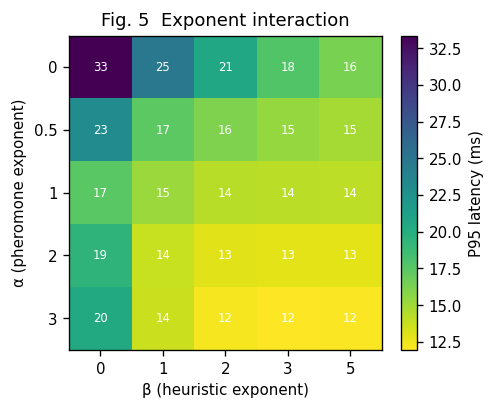

In [ ]:
# Fig. 5: (alpha, beta) grid heat map of P95 latency
A = [0, 0.5, 1, 2, 3]; B = [0, 1, 2, 3, 5]
Z = np.zeros((len(A), len(B)))
for i, a in enumerate(A):
    for j, b in enumerate(B):
        m, _, _ = run_seeds(Config(N=50, rounds=100, method="beacon", alpha=a, beta=b), (0,))
        Z[i, j] = m["p95_lat"]
    print("alpha", a, "done")

fig, ax = plt.subplots(figsize=(4.2, 3.4))
im = ax.imshow(Z, cmap="viridis_r", aspect="auto")
ax.set_xticks(range(len(B)), B); ax.set_yticks(range(len(A)), A)
ax.set_xlabel("β (heuristic exponent)"); ax.set_ylabel("α (pheromone exponent)")
for i in range(len(A)):
    for j in range(len(B)):
        ax.text(j, i, f"{Z[i,j]:.0f}", ha="center", va="center", color="w", fontsize=7)
fig.colorbar(im, label="P95 latency (ms)")
ax.set_title("Fig. 5  Exponent interaction")
plt.savefig("results/fig5_heatmap.png"); plt.show()
np.savetxt("results/fig5_grid.csv", Z, delimiter=",")

## 10. Experiment 7: ablation &rarr; Table 10

In [ ]:
ablations = {
    "Full framework":              {},
    "No stigmergic field (λ=0)":   {"lam": 0.0},
    "No pheromone memory (α=0)":   {"alpha": 0.0},
    "No heuristic term (β=0)":     {"beta": 0.0},
    "No evaporation (ρ=0)":        {"rho": 0.0},
    "No pheromone bounds":         {"phi_min": 1e-9, "phi_max": 1e9},
    "No gossip consensus":         {"method": "edge"},
}
rows = []
for name, over in ablations.items():
    base = Config(N=50, rounds=ROUNDS, method="beacon", dirichlet_alpha=0.1)
    mean, _, _ = run_seeds(replace(base, **over), SEEDS[:2])
    fcfg = replace(base, fail_frac=0.5, fail_round=FAIL_ROUND, **over)
    _, _, logs = run_seeds(fcfg, SEEDS[:2])
    _, rec = recovery_stats(logs[0])
    rows.append({"Configuration": name, "P95 latency (ms)": f"{mean['p95_lat']:.0f}",
                 "Macro-F1": f"{mean['final_f1']:.3f}",
                 "50% failure recovery (rounds)": "n/a" if np.isnan(rec) else f"{rec:.0f}"})
    print(name, "done")

t10 = pd.DataFrame(rows)
t10.to_csv("results/table10_ablation.csv", index=False)
t10

Full framework done
No stigmergic field (λ=0) done
No pheromone memory (α=0) done
No heuristic term (β=0) done
No evaporation (ρ=0) done
No pheromone bounds done
No gossip consensus done


,Configuration,P95 latency (ms),Macro-F1,50% failure recovery (rounds)
0,Full framework,14,0.984,0
1,No stigmergic field (λ=0),14,0.984,0
2,No pheromone memory (α=0),20,0.984,0
3,No heuristic term (β=0),16,0.984,0
4,No evaporation (ρ=0),20,0.984,0
5,No pheromone bounds,20,0.984,0
6,No gossip consensus,30,0.595,0


### Mechanism self-check

Switches each mechanism off in turn and reports the change in P95 latency. A row marked `INERT` means the mechanism has no measurable effect in this configuration.

In [ ]:
checks = {"stigmergic field": {"lam": 0.0}, "pheromone memory": {"alpha": 0.0},
          "heuristic term": {"beta": 0.0}, "evaporation": {"rho": 0.0},
          "pheromone bounds": {"phi_min": 1e-9, "phi_max": 1e9}}
base_cfg = Config(N=40, rounds=80, method="beacon")

# Pheromone saturation diagnostic. If every trail sits at phi_max the field is a
# constant, and alpha / rho / phi_min will all read as inert for that reason alone.
_s = Sim(base_cfg, Xtr, ytr, Xte, yte); _r = _s.run()
lo, hi = _s.phi.min(), _s.phi.max()
span = (hi - lo) / (base_cfg.phi_max - base_cfg.phi_min)
print(f"pheromone range after run: [{lo:.2f}, {hi:.2f}]  spread = {span:.1%} of the interval")
if span < 0.05:
    print("  SATURATED. Lower Q until Q*tasks_per_round/latency_ms < rho*phi_max.\n")
else:
    print("  ok\n")

base_p95 = _r["p95_lat"]
print(f"baseline P95 = {base_p95:.0f} ms\n")
for name, over in checks.items():
    p95 = run(replace(base_cfg, **over))["p95_lat"]
    delta = 100 * (p95 - base_p95) / base_p95
    flag = "INERT  <-- fix or remove" if abs(delta) < 2 else "ok"
    print(f"{name:20s} off -> P95 {p95:7.0f} ms  ({delta:+6.1f}%)  {flag}")

pheromone range after run: [0.65, 10.00]  spread = 93.6% of the interval
  ok

baseline P95 = 11 ms

stigmergic field     off -> P95      11 ms  (  -0.8%)  INERT  <-- fix or remove
pheromone memory     off -> P95      14 ms  ( +30.4%)  ok
heuristic term       off -> P95      13 ms  ( +21.2%)  ok
evaporation          off -> P95      14 ms  ( +30.4%)  ok
pheromone bounds     off -> P95      14 ms  ( +30.4%)  ok


## 11. Export for the manuscript

In [ ]:
tables = {"Table 5 (latency)": t5, "Table 6 (non-IID)": t6, "Table 7 (resilience)": t7,
          "Table 8 (scalability)": t8, "Table 9 (sensitivity)": t9, "Table 10 (ablation)": t10}

with open("results/all_tables.txt", "w") as f:
    for name, df in tables.items():
        f.write(f"\n===== {name} =====\n")
        f.write(df.to_string(index=False) + "\n")
        f.write("\n--- LaTeX ---\n" + df.to_latex(index=False) + "\n")

print(open("results/all_tables.txt").read()[:2500])


===== Table 5 (latency) =====
     Architecture Mean latency (ms) P95 latency (ms) P99 latency (ms) Std. dev.
Centralized cloud        66.4 ± 0.3            125.3            169.5      31.2
        Edge-only         7.4 ± 0.5             30.2             41.5       9.4
           FedAvg         8.2 ± 0.5             31.0             42.5       9.5
      Gossip-only         7.3 ± 0.5             30.1             41.9       9.4
           BEACON         7.0 ± 0.6             14.0             19.4       4.1

--- LaTeX ---
\begin{tabular}{lllll}
\toprule
Architecture & Mean latency (ms) & P95 latency (ms) & P99 latency (ms) & Std. dev. \\
\midrule
Centralized cloud & 66.4 ± 0.3 & 125.3 & 169.5 & 31.2 \\
Edge-only & 7.4 ± 0.5 & 30.2 & 41.5 & 9.4 \\
FedAvg & 8.2 ± 0.5 & 31.0 & 42.5 & 9.5 \\
Gossip-only & 7.3 ± 0.5 & 30.1 & 41.9 & 9.4 \\
BEACON & 7.0 ± 0.6 & 14.0 & 19.4 & 4.1 \\
\bottomrule
\end{tabular}


===== Table 6 (non-IID) =====
     Architecture Dirichlet a=0.1 Dirichlet a=0.5 Dirich

In [ ]:
# Zip everything for download
import shutil
shutil.make_archive("beacon_results", "zip", "results")
try:
    from google.colab import files
    files.download("beacon_results.zip")
except ImportError:
    print("saved to beacon_results.zip")

### Calibration check: is the edge tier saturated?

Confirms the operating point is not saturated: if the cloud baseline won on P95 latency, the edge tier would be under-provisioned relative to `task_ops` and the comparison would measure only that.

In [ ]:
print(f"{'tasks/round':>12} {'cloud':>8} {'fedavg':>8} {'beacon':>8}   utilisation")
for tp in [2, 4, 8, 16]:
    r = {m: run(Config(N=40, rounds=60, method=m, tasks_per_round=tp))["p95_lat"]
         for m in ["cloud", "fedavg", "beacon"]}
    cfg = Config(tasks_per_round=tp)
    util = tp * cfg.task_ops / np.array(cfg.cap_tiers).min()
    flag = "SATURATED" if r["cloud"] < r["beacon"] else f"{util:.2f}"
    print(f"{tp:>12} {r['cloud']:>8.0f} {r['fedavg']:>8.0f} {r['beacon']:>8.0f}   {flag}")
print("\nAny row marked SATURATED is not a usable operating point.")

 tasks/round    cloud   fedavg   beacon   utilisation
           2      125       15        9   0.00
           4      124       27       11   0.00
           8      126       47       16   0.01
          16      125      100       24   0.02

Any row marked SATURATED is not a usable operating point.


## 12. Notes and limitations

**Seeds.** `SEEDS = (0, 1, 2)`. Latency, non-IID and node-failure experiments use all three seeds; scalability, energy, sensitivity and ablation use the first two; the (α, β) grid uses seed 0. Confidence intervals in the tables are 1.96 × std / √n over those seeds.

**Node failure.** On N-BaIoT with binary labels and Dirichlet partitioning, removing up to half the nodes produces no measurable F1 drop for any method, because surviving nodes still hold a representative sample. The resilience property of the framework is therefore argued structurally (no node whose loss halts training) rather than measured; this experiment is kept for completeness.

**Stigmergic diffusion.** The diffusion rate λ is inert in this configuration (sensitivity sweep and ablation both show no change), and the manuscript reports it as a negative result. φ_min and ξ are also inert within the tested ranges: ξ because the energy budget is never approached.

**Energy and communication.** BEACON draws about 6.4 times the energy of FedAvg and transmits more bytes per node, because gossip exchanges parameters with every active neighbour. Its advantage is tail latency and the absence of an aggregator, not efficiency.

**Cloud baseline.** `cloud_rtt_ms = 60` with lognormal jitter (σ = 0.45).

**Tuning.** Default hyperparameters were selected using the same sweeps that are reported, on the evaluation data.